# Chapter 38: Physics: rotations, inertia and quantum states

The code for this chapter from [*Matrices in Practice*](https://trgoodale.github.io/matrix-book/part-6/38-physics.html), by Tom Goodale.

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/trgoodale/matrix-book/blob/main/code/python/38-physics.ipynb)

Run the cells in order, from the top: later cells use variables set in earlier ones. Change the numbers and run them again to see what happens. The code needs NumPy, SciPy and Matplotlib (and pandas in a few chapters), all of which Colab already has.

Code licensed under the [MIT licence](https://trgoodale.github.io/matrix-book/LICENSE.md).

### Code for Figure 38.2

This draws [Figure 38.2](https://trgoodale.github.io/matrix-book/part-6/38-physics.html#fig-rabi) in the chapter. You don't need it for the rest of the notebook.

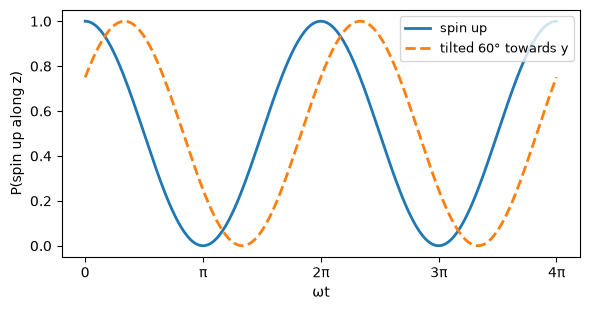

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import expm

sx = np.array([[0, 1], [1, 0]])
t = np.linspace(0, 4 * np.pi, 300)                      # in units of 1/ω
starts = {"spin up": np.array([1, 0]),
          "tilted 60° towards y": np.array([np.cos(np.pi / 6), 1j * np.sin(np.pi / 6)])}

fig, ax = plt.subplots(figsize=(6, 3.2))
for (label, psi0), style in zip(starts.items(), ["-", "--"]):
    p = [abs((expm(-1j * sx * tk / 2) @ psi0)[0])**2 for tk in t]
    ax.plot(t, p, style, lw=2, label=label)
ax.set_xlabel("ωt")
ax.set_ylabel("P(spin up along z)")
ax.set_xticks(np.arange(0, 4 * np.pi + 0.1, np.pi), ["0", "π", "2π", "3π", "4π"])
ax.legend(fontsize=9)
plt.tight_layout()
plt.show()

## In code

The code finds the principal axes of four point masses in an L shape, and applies a quantum time evolution.

In [2]:
import numpy as np
from scipy.linalg import expm

# Inertia tensor of four 1 kg masses in an L shape, about their centre of mass
r = np.array([[0, 0, 0], [1, 0, 0], [2, 0, 0], [0, 1, 0]], dtype=float)
m = np.ones(4)
r = r - m @ r / m.sum()                    # positions relative to the centre of mass
I = sum(mk * ((rk @ rk) * np.eye(3) - np.outer(rk, rk)) for mk, rk in zip(m, r))
print(I)
moments, axes = np.linalg.eigh(I)          # I is symmetric
print(moments)
print(axes)                                # principal axes as columns

# Spin up, evolving under sigma_x for omega t = pi/2
sx = np.array([[0, 1], [1, 0]])
psi = expm(-1j * sx * np.pi / 4) @ np.array([1, 0])
print(np.abs(psi)**2)                      # probabilities of up and down along z

[[0.75 0.75 0.  ]
 [0.75 2.75 0.  ]
 [0.   0.   3.5 ]]
[0.5 3.  3.5]
[[-0.9486833   0.31622777  0.        ]
 [ 0.31622777  0.9486833   0.        ]
 [ 0.          0.          1.        ]]
[0.5 0.5]


## Exercises

The code exercises from the [end of the chapter](https://trgoodale.github.io/matrix-book/part-6/38-physics.html#sec-physics-exercises). Worked solutions are in the notebook `solutions-part-6.ipynb`, and in the [book's solutions](https://trgoodale.github.io/matrix-book/appendices/solutions-6.html#sec-solutions-physics).

### Exercise 6

A quantum computer applies the **Hadamard gate** $\mathbf{H} = \tfrac{1}{\sqrt{2}}\begin{pmatrix}1 & 1 \\ 1 & -1\end{pmatrix}$ to a qubit. Check that $\mathbf{H}$ is symmetric and orthogonal, and that $\mathbf{H}^2 = \mathbf{I}$. Starting from $(1, 0)^{\mathsf{T}}$, apply $\mathbf{H}$, then a phase gate $\begin{pmatrix}1 & 0 \\ 0 & e^{i\phi}\end{pmatrix}$, then $\mathbf{H}$ again, and plot the probability of measuring $(1, 0)^{\mathsf{T}}$ as $\phi$ runs from 0 to $2\pi$. (This is the core of a quantum interferometer.)

In [3]:
# Your code here